## Computation of exercises on `10-logistic-regression.rnote`

In [1]:
import numpy as np
import pandas as pd

In [2]:
np.set_printoptions(precision=3, suppress=True, legacy="1.25")
np.set_printoptions(precision=3, suppress=True)    # NumPy arrays
pd.set_option("display.float_format", "{:.3f}".format)  # pandas DataFrames/Series
#%precision 3                                         # plain Python floats in cell output

**1.** Considere el modelo

$$
p(\mathbf{x}) = P(y = 1 \mid \mathbf{x}) = \sigma(-0.8 + 1.2x_1 - 0.5x_2).
$$

Para cada uno de los puntos $\mathbf{x}^{(1)} = (1, 2)^T$, $\mathbf{x}^{(2)} = (2, -1)^T$ y $\mathbf{x}^{(3)} = (0, 0)^T$:

- **a)** calcule el predictor lineal $z$;
- **b)** halle $P(y = 1 \mid \mathbf{x})$ y $P(y = 0 \mid \mathbf{x})$;
- **c)** determine la clase predicha.

In [3]:
X = np.array([
    [1, 1, 2],
    [1, 2, -1],
    [1, 0, 0]
])

b = np.array([-0.8, 1.2, -0.5])

# item a
sigmoid = lambda z: 1/(1+np.exp(-z)) 
z = X@b
print(f"z={z}")

# item b
p = sigmoid(z)
print(f"p={p}") # P(y=1|x), by other way: P(y=0|x) = 1 - P(y=1|x) [or 1-p]

# item c
threshold = 0.5
y_hat = (p > 0.5).astype(int)
print(f"y_hat={y_hat}")

z=[-0.6  2.1 -0.8]
p=[0.354 0.891 0.31 ]
y_hat=[0 1 0]


**2.** Un modelo produce las probabilidades siguientes:

$$
\begin{array}{c|ccccc}
\text{observación} & A & B & C & D & E \\
\hline
p_i & 0.18 & 0.42 & 0.50 & 0.67 & 0.91
\end{array}
$$

Determine las clases predichas al usar los umbrales $0.3$, $0.5$ y $0.7$. Describa qué ocurre con la cantidad de observaciones clasificadas como clase $1$ cuando el umbral aumenta.

In [4]:
p = pd.Series([0.18, 0.42, 0.5, 0.67, 0.91], index=["A", "B", "C", "D", "E"])
thresholds = [0.3, 0.5, 0.7]

y_hat = pd.DataFrame(columns=["threshold"]+p.index.tolist())
for t in thresholds:
    mask = p > t
    print(f"t={t}, ones={sum(mask)}, obs={p.index[mask].tolist()}")
    #import pdb; pdb.set_trace()
    y_hat.loc[len(y_hat)] = [t] + mask.tolist()

print("\n\nIs 'one' with threshold?")
y_hat

t=0.3, ones=4, obs=['B', 'C', 'D', 'E']
t=0.5, ones=2, obs=['D', 'E']
t=0.7, ones=1, obs=['E']


Is 'one' with threshold?


,threshold,A,B,C,D,E
0,0.300,False,True,True,True,True
1,0.500,False,False,False,True,True
2,0.700,False,False,False,False,True


**3.** Sea

$$
p(\mathbf{x}) = \sigma(1 - 2x_1 + 0.5x_2).
$$

- **a)** Obtenga la ecuación de la frontera de decisión para un umbral de $0.5$ y escríbala en la forma $x_2 = m x_1 + b$.
- **b)** Clasifique los puntos $(0, 0)^T$, $(1, 1)^T$ y $(2, 8)^T$.
- **c)** Dibuje la frontera e indique en qué semiplano se predice la clase $1$.

In [5]:
# question 3 [item c]

X = np.array([
    [1, 0, 0],
    [1, 1, 1],
    [1, 2, 8]
])
b = np.array([1, -2, 0.5])
z = X@b

sigmoid = lambda z: 1/(1+np.exp(-z)) 
p = sigmoid(z)
print(f"p={p}")

threshold = 0.5
y_hat = (p > 0.5).astype(int)
print(f"y_hat={y_hat}")

p=[0.731 0.378 0.731]
y_hat=[1 0 1]


**4.** Demuestre que, para $p(\mathbf{x}) = \sigma(\beta_0 + \beta_1 x_1 + \beta_2 x_2)$, la frontera correspondiente a un umbral $t \in (0, 1)$ satisface

$$
\beta_0 + \beta_1 x_1 + \beta_2 x_2 = \ln\left(\frac{t}{1 - t}\right).
$$

Después encuentre la frontera del modelo del ejercicio anterior cuando $t = 0.7$ y compárela con la frontera obtenida para $t = 0.5$.

In [16]:
# question 4 - threshold comparison

b0, b1, b2 = 1, -2, 0.5 # question 3

thresholds = [0.5, 0.7, 0.9]
intersections = {}
for t in thresholds:
    logit = np.log(t / (1 - t))
    intersections[t] = [
        (0, round((logit-b0) / b2, 3)),
        (round((logit-b0) / b1, 3), 0)
    ]
    print(f"[t={t}] intersections={intersections[t]}")

[t=0.5] intersections=[(0, -2.0), (0.5, 0)]
[t=0.7] intersections=[(0, -0.305), (0.076, 0)]
[t=0.9] intersections=[(0, 2.394), (-0.599, 0)]


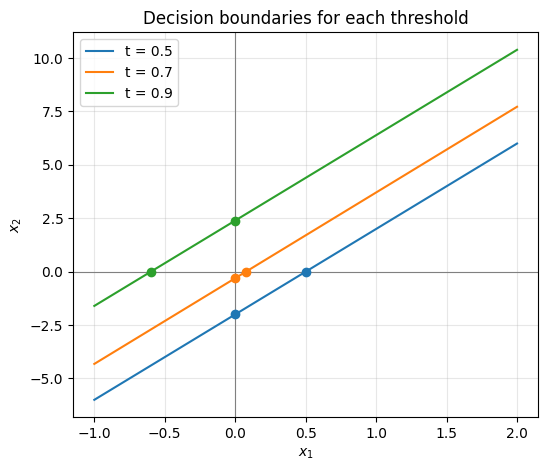

In [17]:
import matplotlib.pyplot as plt

x1 = np.linspace(-1, 2, 200)

fig, ax = plt.subplots(figsize=(6, 5))
for t, ((xa, ya), (xb, yb)) in intersections.items():
    slope = (yb - ya) / (xb - xa)
    x2 = ya + slope * (x1 - xa)               # line through both points
    line, = ax.plot(x1, x2, label=f"t = {t}")
    ax.scatter([xa, xb], [ya, yb], color=line.get_color(), zorder=3)

ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Decision boundaries for each threshold")
ax.legend()
ax.grid(alpha=0.3)
plt.savefig("Q4-border_equation_multiple_thresholds.png")
plt.show()

**6.** Para cuatro observaciones se tienen

$$
\mathbf{y} = (1, 0, 1, 0)^T, \qquad \mathbf{p} = (0.8, 0.4, 0.7, 0.3)^T.
$$

- **a)** Evalúe cada factor $p_i^{y_i}(1 - p_i)^{1 - y_i}$.
- **b)** Calcule la verosimilitud $L = \prod_{i=1}^{4} p_i^{y_i}(1 - p_i)^{1 - y_i}$.
- **c)** Calcule $\ln L$ y verifique que coincide con $\sum_{i=1}^{4} \left[ y_i \ln p_i + (1 - y_i) \ln(1 - p_i) \right]$.

In [24]:
p = np.array([0.8, 0.4, 0.7, 0.3])
y = np.array([1, 0, 1, 0])

In [ ]:
# item a

#[ REASONING ]
p**y, (1-p)**(1-y) # this mean take p if y=1, otherwise take 1-p (this is a binary event)
# EXTRA: for y = 0, 1-p is being taken, on the other field 1 is put (to later multipy with p**y (which take the ones with y=1)

p**y*(1-p)**(1-y)

In [26]:
# item b
L = np.prod(p**y*(1-p)**(1-y))
L

0.23519999999999996

In [27]:
# item c
np.log(L), np.sum(y*np.log(p) + (1-y)*np.log(1-p))

(-1.4473190629576653, -1.4473190629576653)

**7.** Considere

$$
X = \begin{pmatrix} 1 & 0 & 1 \\ 1 & 1 & 0 \\ 1 & 1 & 1 \\ 1 & 2 & -1 \end{pmatrix}, \qquad
\mathbf{y} = \begin{pmatrix} 0 \\ 1 \\ 1 \\ 0 \end{pmatrix}, \qquad
\boldsymbol{\beta} = \begin{pmatrix} -0.5 \\ 0.8 \\ -0.4 \end{pmatrix}.
$$

- **a)** Calcule $\mathbf{z} = X\boldsymbol{\beta}$ y $p_i = \sigma(z_i)$.
- **b)** Halle la verosimilitud de las etiquetas observadas.
- **c)** Calcule la entropía cruzada binaria promedio

$$
E(\boldsymbol{\beta}) = -\frac{1}{4} \sum_{i=1}^{4} \left[ y_i \ln p_i + (1 - y_i) \ln(1 - p_i) \right].
$$

In [29]:
X = np.array([
    [1, 0, 1],
    [1, 1, 0],
    [1, 1, 1],
    [1, 2, -1]
])

y = np.array([0, 1, 1, 0])
b = np.array([-0.5, 0.8, -0.4])

In [33]:
# item a
z = X@b
print(f"z={z}")

p = 1/(1+np.exp(-z)) # sigmoid(z)
print(f"p={p}")

z=[-0.9  0.3 -0.1  1.5]
p=[0.289 0.574 0.475 0.818]


In [35]:
# item b
L = np.prod(p**y*(1-p)**(1-y)) # verosimilitud
L

0.03539024516039655

In [36]:
# item c
(-1/4.0)*np.log(L) # avg binary cross entropy 

0.8353297643142346